# Hardware results on Quantinuum Helios (Fig. 3 and Table `tab:performance_results`)

Success probability and expected approximation ratio of standalone QAOA vs qReduMIS ($p=2$) on the first kernel of each stock-market index. The values (with 95% bootstrap CIs) are those reported in `tab:performance_results`; they were computed from the raw per-shot hardware results, which are not part of this release.

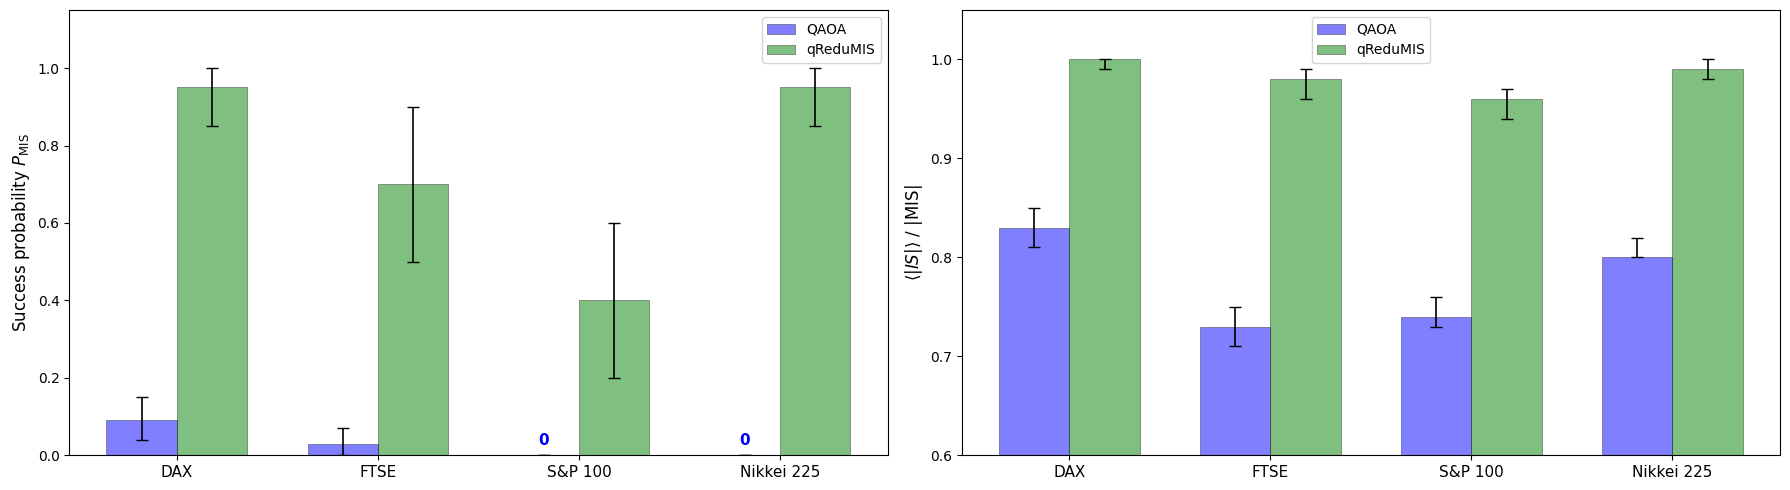

,P_MIS QAOA,P_MIS qReduMIS,optTTS QAOA,optTTS qReduMIS,AR QAOA,AR qReduMIS
DAX,"0.09 [0.04, 0.15]","0.95 [0.85, 1.00]","48.83 [28.34, 112.81]","35.56 [24.97, 52.84]","0.83 [0.81, 0.85]","1.00 [0.99, 1.00]"
FTSE,"0.03 [0.00, 0.07]","0.70 [0.50, 0.90]","151.19 [63.46, 458.21]","185.58 [88.58, 286.41]","0.73 [0.71, 0.75]","0.98 [0.96, 0.99]"
S&P 100,0.00,"0.40 [0.20, 0.60]",inf,"468.67 [215.28, 1181.40]","0.74 [0.73, 0.76]","0.96 [0.94, 0.97]"
Nikkei 225,0.00,"0.95 [0.85, 1.00]",inf,"88.58 [49.94, 123.49]","0.80 [0.80, 0.82]","0.99 [0.98, 1.00]"


In [1]:
%matplotlib inline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SAVE_FIGURES = False  # set False to skip saving figures
# Figures go to <release root>/figures (the notebook runs from notebooks/)
FIG_DIR = os.path.join(os.path.abspath(os.pardir), "figures")

# ── Hardware results (Helios, p=2), 95% bootstrap CIs — Table tab:performance_results
indexes = ["DAX", "FTSE", "S&P 100", "Nikkei 225"]

# Success probability
ps_qaoa     = [0.09, 0.03, 0.00, 0.00]
ps_qaoa_lo  = [0.04, 0.00, 0.00, 0.00]
ps_qaoa_hi  = [0.15, 0.07, 0.00, 0.00]

ps_qred     = [0.95, 0.70, 0.40, 0.95]
ps_qred_lo  = [0.85, 0.50, 0.20, 0.85]
ps_qred_hi  = [1.00, 0.90, 0.60, 1.00]

# optTTS (table only; inf = no success)
tts_qaoa     = [48.83, 151.19, np.inf, np.inf]
tts_qaoa_lo  = [28.34,  63.46, np.inf, np.inf]
tts_qaoa_hi  = [112.81, 458.21, np.inf, np.inf]

tts_qred     = [35.56, 185.58, 468.67, 88.58]
tts_qred_lo  = [24.97,  88.58, 215.28, 49.94]
tts_qred_hi  = [52.84, 286.41, 1181.40, 123.49]

# Expected approximation ratio
ar_qaoa     = [0.83, 0.73, 0.74, 0.80]
ar_qaoa_lo  = [0.81, 0.71, 0.73, 0.80]
ar_qaoa_hi  = [0.85, 0.75, 0.76, 0.82]

ar_qred     = [1.00, 0.98, 0.96, 0.99]
ar_qred_lo  = [0.99, 0.96, 0.94, 0.98]
ar_qred_hi  = [1.00, 0.99, 0.97, 1.00]


def ci_err(vals, lo, hi):
    """Asymmetric error bars from CIs."""
    return [np.array(vals) - np.array(lo), np.array(hi) - np.array(vals)]


# ── Figure 3: success probability (left) and approximation ratio (right) ──
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
x = np.arange(len(indexes))
w = 0.35
colors_qaoa, colors_qred = "blue", "green"

ax = axes[0]
ax.bar(x - w/2, ps_qaoa, w, label="QAOA",
       color=colors_qaoa, alpha=0.5, edgecolor="k", linewidth=0.5,
       yerr=ci_err(ps_qaoa, ps_qaoa_lo, ps_qaoa_hi),
       capsize=4, error_kw={"linewidth": 1.2})
ax.bar(x + w/2, ps_qred, w, label="qReduMIS",
       color=colors_qred, alpha=0.5, edgecolor="k", linewidth=0.5,
       yerr=ci_err(ps_qred, ps_qred_lo, ps_qred_hi),
       capsize=4, error_kw={"linewidth": 1.2})
for i, ps in enumerate(ps_qaoa):
    if ps == 0:
        ax.annotate("0", (x[i] - w/2, 0.02), ha="center", va="bottom",
                    fontsize=11, fontweight="bold", color=colors_qaoa)
ax.set_ylabel("Success probability $P_{\\mathrm{MIS}}$", fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(indexes, fontsize=11)
ax.set_ylim(0, 1.15)
ax.legend(fontsize=10)

ax = axes[1]
ax.bar(x - w/2, ar_qaoa, w, label="QAOA",
       color=colors_qaoa, alpha=0.5, edgecolor="k", linewidth=0.5,
       yerr=ci_err(ar_qaoa, ar_qaoa_lo, ar_qaoa_hi),
       capsize=4, error_kw={"linewidth": 1.2})
ax.bar(x + w/2, ar_qred, w, label="qReduMIS",
       color=colors_qred, alpha=0.5, edgecolor="k", linewidth=0.5,
       yerr=ci_err(ar_qred, ar_qred_lo, ar_qred_hi),
       capsize=4, error_kw={"linewidth": 1.2})
ax.set_ylabel(r"$\langle |IS| \rangle$ / |MIS|", fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(indexes, fontsize=11)
ax.set_ylim(0.6, 1.05)
ax.legend(fontsize=10)

plt.tight_layout()
if SAVE_FIGURES:
    os.makedirs(FIG_DIR, exist_ok=True)
    plt.savefig(os.path.join(FIG_DIR, "comparison_hw_results_reduced_with_inf_success_prob.png"),
                dpi=300, bbox_inches="tight")
plt.show()


# ── Table tab:performance_results ─────────────────────────────────────
def _fmt(v, lo, hi, nd=2):
    if not np.isfinite(v):
        return "inf"
    if v == lo == hi:
        return f"{v:.{nd}f}"
    return f"{v:.{nd}f} [{lo:.{nd}f}, {hi:.{nd}f}]"

table = pd.DataFrame({
    "P_MIS QAOA":      [_fmt(*t) for t in zip(ps_qaoa, ps_qaoa_lo, ps_qaoa_hi)],
    "P_MIS qReduMIS":  [_fmt(*t) for t in zip(ps_qred, ps_qred_lo, ps_qred_hi)],
    "optTTS QAOA":     [_fmt(*t) for t in zip(tts_qaoa, tts_qaoa_lo, tts_qaoa_hi)],
    "optTTS qReduMIS": [_fmt(*t) for t in zip(tts_qred, tts_qred_lo, tts_qred_hi)],
    "AR QAOA":         [_fmt(*t) for t in zip(ar_qaoa, ar_qaoa_lo, ar_qaoa_hi)],
    "AR qReduMIS":     [_fmt(*t) for t in zip(ar_qred, ar_qred_lo, ar_qred_hi)],
}, index=indexes)
table
